# Week 09 — CT Scanner Generations, the Sinogram & Back-Projection

The companion to last lecture's **algebraic reconstruction**: how real scanners *acquire* projections,
and the **back-projection** route to an image. Topics (from Lecture 2):

1. **Generations of CT scanners** — from Hounsfield's 1st-generation pencil-beam rig to modern
   **helical multi-slice** systems, plus the **C-arm / fluoroscopy** and the radiation-dose motivation.
2. **The sinogram** = projections stacked over angle; how it is computed by **rotate-and-sum**.
3. **The Radon transform** — a point maps to a **sinusoid** (hence *sino*-gram); and the fact that for
   binary images the Radon transform is the **Hough transform**, a line detector.
4. **Back-projection** — why an unfiltered reconstruction (a **laminogram**) has a blurry **halo**, how
   the **ramp filter** fixes it, and how the image builds up **sweep by sweep**.

> The **power-analysis / cohort-size** material from this lecture lives in
> `CohortSizeDetermination.ipynb`; the head-to-head **method comparison** lives in
> `ReconstructionMethods_Compare.ipynb` and `FourierTheory_Parseval_CT.ipynb`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import rotate
from scipy.signal import find_peaks
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, resize

plt.rcParams["figure.dpi"] = 110
phantom = resize(shepp_logan_phantom(), (128, 128), anti_aliasing=True)

## 1. Generations of CT scanners

Each generation reduced **scan time** and **patient dose** by rethinking the beam/detector geometry
and the mechanical motion:

| Generation | Beam & detector | Motion | Speed | Key idea |
|---|---|---|---|---|
| **1st** (1975) | single **pencil** beam → single detector | translate **and** rotate | slow (minutes) | Hounsfield's EMI rig; many translations per angle, high dose |
| **2nd** | narrow **fan** beam → small detector array | translate + rotate (fewer steps) | ~20 s / slice | wider detector catches several rays at once |
| **3rd** | **fan** beam → detector **arc**, both rotate together | rotate only (no translation) | ~0.5 s / rotation | fewest moving parts; the common modern layout |
| **4th** | **fan** beam → full stationary detector **ring** | only the tube rotates | fast | curvilinear detectors need flat-field corrections |
| **Multi-slice** | thick fan along **z** → multi-row detectors | rotate | several slices / rotation | more coverage per spin |
| **Helical / spiral** | multi-row + **continuous patient translation** | rotate **while** the table moves | whole volume in ~1 s | 64–256 slices; a 3-D volume quickly |

The trend is always toward **cleaner parallel/fan beams**, **fewer moving parts**, and **less dose**
for the same diagnostic information.

## 2. C-arm / fluoroscopy and the dose motivation

A **C-arm** is a mobile C-shaped source–detector pair (now a **digital flat panel**) that rotates in
many degrees of freedom to give **fluoroscopic** (live X-ray) views from any angle — used *during*
procedures such as **VT ablation**. Long procedures mean long exposure, and X-rays are **ionizing**:
beyond DNA-altering photoelectric/Compton effects, prolonged fluoroscopy can cause real
**radiation burns**. Co-registering the live C-arm view with **pre-op CT/SPECT** (structural +
functional targets) lets surgeons cut fluoroscopy time — the clinical payoff of dose awareness.

This is *why* every scanner generation above chases lower dose, and why the math of **dosimetry**
(next topics) matters.

## 3. The sinogram: projections by “rotate-and-sum”

A **projection** is just the **sum of pixels along a direction**. Rather than tracing slanted rays
across a fixed grid, software **rotates the image** and sums **top-to-bottom** — resampling onto a
rectilinear grid at each angle (bilinear interpolation). Stacking those projection columns over all
angles is the **sinogram** (Radon space). Below, our hand-rolled rotate-and-sum matches
`skimage.transform.radon` closely.

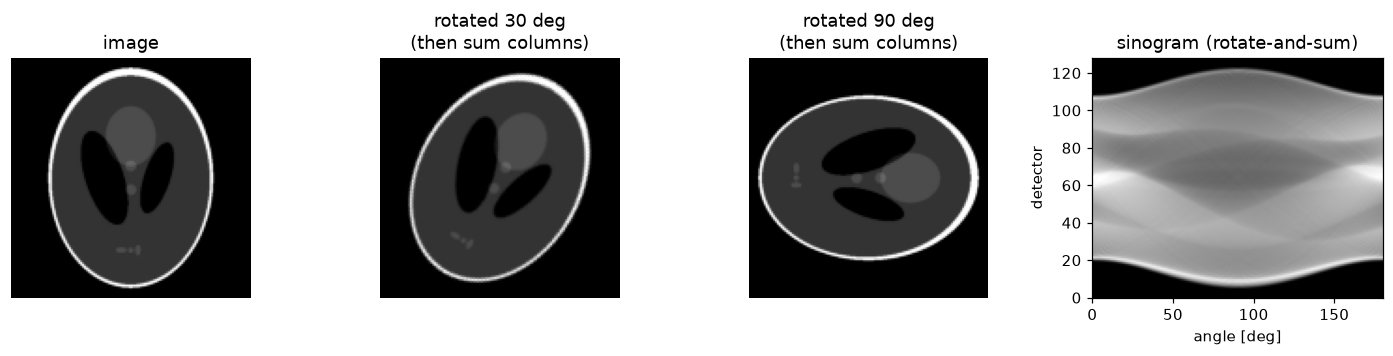

rotate-and-sum vs skimage radon: correlation = 0.978


In [2]:
theta = np.arange(0.0, 180.0, 1.0)

def rotate_and_sum(image, theta):
    """Sinogram by rotating the image and summing columns (top-down) at each angle."""
    sino = np.zeros((image.shape[0], len(theta)))
    for i, a in enumerate(theta):
        sino[:, i] = rotate(image, -a, reshape=False, order=1).sum(axis=0)
    return sino

sino_rs = rotate_and_sum(phantom, theta)
sino_sk = radon(phantom, theta=theta, circle=True)
corr = np.corrcoef(sino_rs.ravel(), sino_sk.ravel())[0, 1]

fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("image"); ax[0].axis("off")
for a, ang in zip(ax[1:3], [30, 90]):
    ax_rot = rotate(phantom, -ang, reshape=False, order=1)
    a.imshow(ax_rot, cmap="gray"); a.set_title(f"rotated {ang} deg\n(then sum columns)"); a.axis("off")
ax[3].imshow(sino_rs, cmap="gray", aspect="auto", extent=(0, 180, 0, phantom.shape[0]))
ax[3].set_title("sinogram (rotate-and-sum)"); ax[3].set_xlabel("angle [deg]"); ax[3].set_ylabel("detector")
plt.tight_layout(); plt.show()
print(f"rotate-and-sum vs skimage radon: correlation = {corr:.3f}")

## 4. Why “sino”-gram: a point becomes a sinusoid

The **Radon transform** (Radon, 1917) maps the Cartesian image to projection (Radon) space. A single
bright **point** at radius $r$ from the center projects to detector position $r\cos(\theta-\phi)$ — a
**sinusoid** in the sinogram. That is literally why the output is called a *sinogram*. Several points
give several overlaid sinusoids, each with amplitude set by its distance from the rotation center.

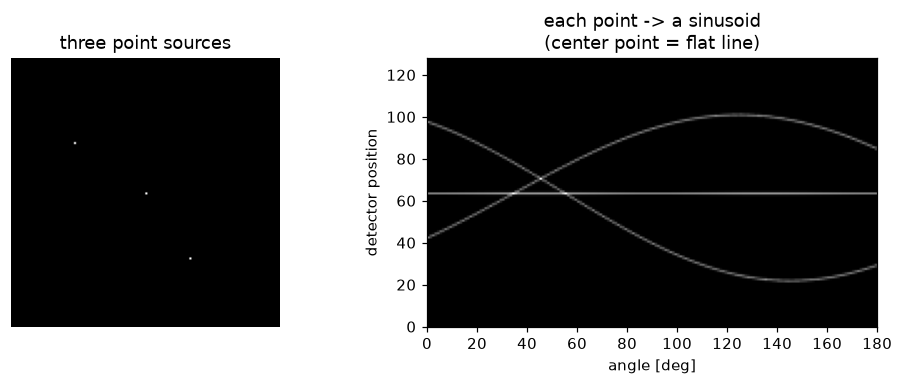

In [3]:
points = np.zeros((128, 128))
for (y, x) in [(40, 30), (64, 64), (95, 85)]:
    points[y, x] = 1.0
sino_pts = radon(points, theta=theta, circle=True)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].imshow(points, cmap="gray"); ax[0].set_title("three point sources"); ax[0].axis("off")
ax[1].imshow(sino_pts, cmap="gray", aspect="auto", extent=(0, 180, 0, points.shape[0]))
ax[1].set_title("each point -> a sinusoid\n(center point = flat line)")
ax[1].set_xlabel("angle [deg]"); ax[1].set_ylabel("detector position")
plt.tight_layout(); plt.show()

## 5. Radon = Hough transform: counting lines

For a **binary** image the Radon transform is the **Hough transform** — a classic **line detector**. A
straight line integrates to a strong peak at the angle **perpendicular** to it, so the **number of
peaks** equals the **number of lines**. Below, three lines (two vertical, one diagonal) produce three
bright peaks in Radon space.

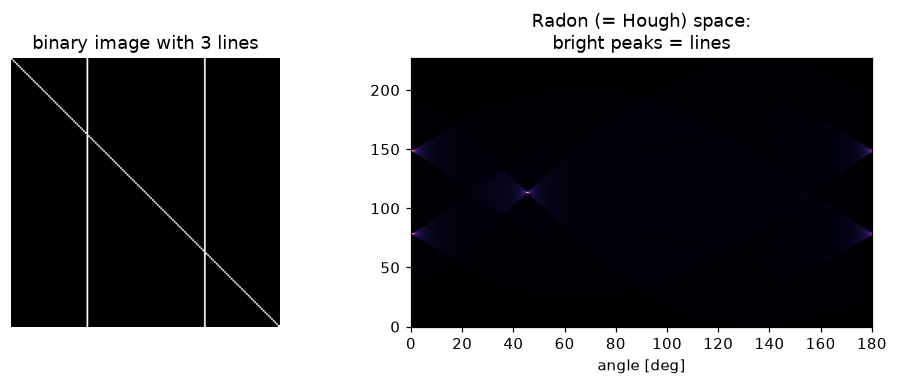

vertical lines detected as peaks at 0 deg: 2


In [4]:
N = 160
lines = np.zeros((N, N))
lines[:, 45] = 1.0                       # vertical line 1
lines[:, 115] = 1.0                      # vertical line 2
d = np.arange(N); lines[d, d] = 1.0      # diagonal line

rad = radon(lines, theta=theta, circle=False)

# the two vertical lines peak at angle 0; count them along that column
col0 = rad[:, 0]
peaks, _ = find_peaks(col0, height=col0.max() * 0.5)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].imshow(lines, cmap="gray"); ax[0].set_title("binary image with 3 lines"); ax[0].axis("off")
ax[1].imshow(rad, cmap="magma", aspect="auto", extent=(0, 180, 0, rad.shape[0]))
ax[1].set_title("Radon (= Hough) space:\nbright peaks = lines"); ax[1].set_xlabel("angle [deg]")
plt.tight_layout(); plt.show()
print(f"vertical lines detected as peaks at 0 deg: {len(peaks)}")

## 6. Back-projection: the laminogram halo and the ramp filter

**Back-projection** smears each projection back across the image and sums. But the **center of k-space**
is sampled by *every* projection, so low frequencies are massively over-represented — plain
back-projection yields a **laminogram** with a blurry **$1/r$ halo**. The fix is **filtered
back-projection**: multiply each projection's spectrum by a **ramp (V-shaped) filter** $|k|$ that
down-weights the center and lifts the high frequencies, removing the halo and restoring edges.

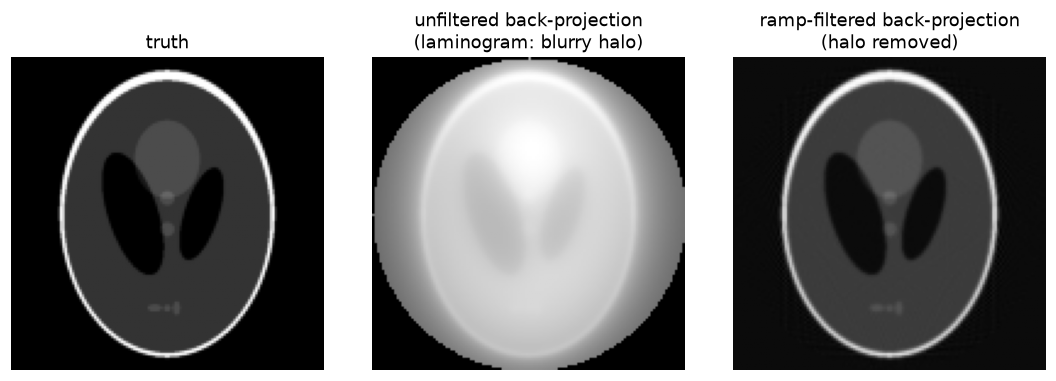

In [5]:
sino = radon(phantom, theta=theta, circle=True)
laminogram = iradon(sino, theta=theta, filter_name=None, circle=True)   # unfiltered back-projection
fbp = iradon(sino, theta=theta, filter_name="ramp", circle=True)        # ramp-filtered

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(laminogram, cmap="gray"); ax[1].set_title("unfiltered back-projection\n(laminogram: blurry halo)"); ax[1].axis("off")
ax[2].imshow(fbp, cmap="gray"); ax[2].set_title("ramp-filtered back-projection\n(halo removed)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 7. Building the image sweep by sweep

Each filtered projection is one **sweep** of a paintbrush across the accumulator. The more angular
sweeps we add, the sharper and more complete the reconstruction — few sweeps leave visible streaks,
many sweeps converge to the image.

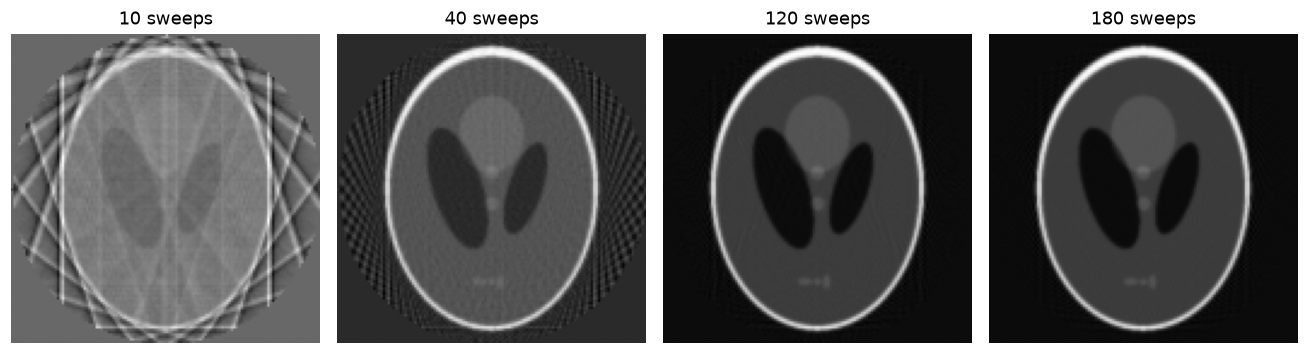

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for a, n_views in zip(ax, [10, 40, 120, 180]):
    th = np.linspace(0.0, 180.0, n_views, endpoint=False)
    s = radon(phantom, theta=th, circle=True)
    rec = iradon(s, theta=th, filter_name="ramp", circle=True)
    a.imshow(rec, cmap="gray"); a.set_title(f"{n_views} sweeps"); a.axis("off")
plt.tight_layout(); plt.show()

## Takeaways

- **CT scanner generations** trade mechanical motion for speed and dose: pencil→fan→ring beams, then
  **multi-slice** and **helical** acquisition for whole-volume scans in ~1 s.
- **Fluoroscopy / C-arm** gives live intra-procedural views but accumulates **ionizing dose**;
  pre-op image fusion reduces exposure.
- A **sinogram** is projections vs angle, computed by **rotate-and-sum**; the **Radon transform** sends
  a point to a **sinusoid** (hence the name) and, for binary images, *is* the **Hough** line detector.
- Plain **back-projection** over-weights low frequencies → a **laminogram halo**; the **ramp filter**
  $|k|$ corrects the balance (**filtered back-projection**).
- Reconstruction builds up **sweep by sweep**: more projection angles → fewer streaks, sharper image.
- Next: a head-to-head of **direct Fourier**, **FBP**, and **algebraic** reconstruction
  (`ReconstructionMethods_Compare.ipynb`).